In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

# BHP: RieszNet

## Library Imports

In [3]:
from pathlib import Path
import os
import glob
from joblib import dump, load
import pandas as pd
import scipy
import scipy.stats
import scipy.special
import torch
import torch.nn as nn
import numpy as np
import math
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_predict
from utils.NN_avgmom_sim import sim_fun
from utils.moments import avg_small_diff

## NN settings

In [4]:
drop_prob = 0.0  # dropout prob of dropout layers throughout notebook
n_hidden = 100  # width of hidden layers throughout notebook

# Training params
learner_lr = 1e-4
learner_l2 = 1e-3
n_epochs = 300
earlystop_rounds = 20 # how many epochs to wait for an out-of-sample improvement
earlystop_delta = 1e-3
bs = 64

In [5]:
fast_train_opt = {'earlystop_rounds' : 2, 'earlystop_delta' : earlystop_delta,
                  'learner_lr' : 1e-3, 'learner_l2' : learner_l2, 'learner_l1' : 0.0,
                  'n_epochs' : 100, 'bs' : bs, 'target_reg' : 1, 'riesz_weight' : 0.1,
                  'optimizer' : 'adam'}
            
train_opt = {'earlystop_rounds' : earlystop_rounds, 'earlystop_delta' : earlystop_delta,
             'learner_lr' : learner_lr, 'learner_l2' : learner_l2, 'learner_l1' : 0.0,
             'n_epochs' : n_epochs, 'bs' : bs, 'target_reg' : 1, 'riesz_weight' : 0.1,
             'optimizer' : 'adam'}         

## Read Data

In [6]:
df = pd.read_csv('./data/BHP/data_BHP2.csv')
df = df[df["log_p"] > math.log(1.2)]
df = df[df["log_y"] > math.log(15000)]
Xdf = df.iloc[:,1:]
X_nostatedum = Xdf.drop(["distance_oil1000", "share"], axis=1).values
columns = Xdf.columns
state_dum = pd.get_dummies(Xdf['state_fips'], prefix="state", dtype=float)
Xdf = pd.concat([Xdf, state_dum], axis = 1)
Xdf = Xdf.drop(["distance_oil1000", "state_fips", "share"], axis=1)
W = Xdf.drop(["log_p"], axis=1).to_numpy(dtype=float)
T = Xdf['log_p'].to_numpy(dtype=float)

## Generate Semi-Synthetic Treatment

In [7]:
# Conditional Mean
mu_T = RandomForestRegressor(n_estimators = 100, min_samples_leaf = 50, random_state = 123)
mu_T.fit(W, T)

# Conditional Variance
sigma2_T = RandomForestRegressor(n_estimators = 100, min_samples_leaf = 50, max_depth = 5, random_state = 123)
e_T = T - cross_val_predict(mu_T, W, T)
sigma2_T.fit(W, e_T ** 2)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",50
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",123
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of

In [8]:
def gen_T(W): # T ~ N(\mu(W), \sigma^2(W))
    n = W.shape[0]
    return (mu_T.predict(W) + np.sqrt(sigma2_T.predict(W)) * np.random.normal(size=(n,))).reshape(-1,1)

def true_rr(X):
    return (X[:, 0] - mu_T.predict(X[:, 1:]))/(sigma2_T.predict(X[:, 1:]))

## Run Simulations

Now trying true_f_simple_lin_conf


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 28 concurrent workers.
[Parallel(n_jobs=-1)]: Done 100 out of 100 | elapsed: 10.5min finished


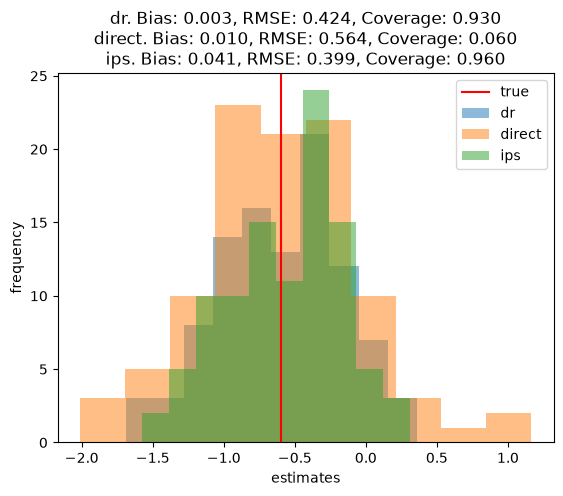

Now trying true_f_simple_nonlin_conf


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 28 concurrent workers.
[Parallel(n_jobs=-1)]: Done 100 out of 100 | elapsed: 12.6min finished


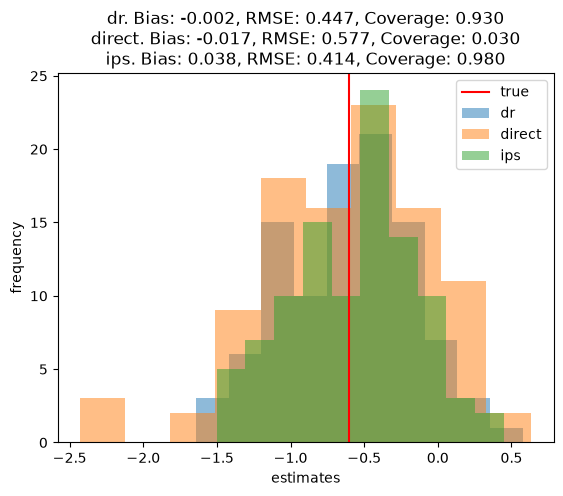

Now trying true_f_compl_lin_conf


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 28 concurrent workers.
[Parallel(n_jobs=-1)]: Done 100 out of 100 | elapsed: 12.2min finished


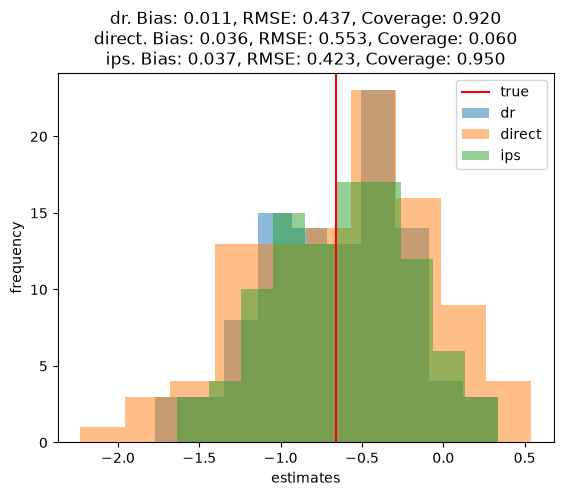

Now trying true_f_compl_nonlin_conf


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 28 concurrent workers.
[Parallel(n_jobs=-1)]: Done 100 out of 100 | elapsed: 10.7min finished


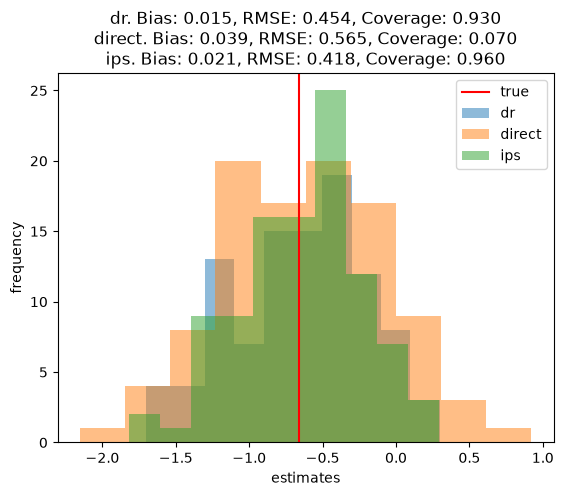

Now trying true_f_simple_lin_conf


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 28 concurrent workers.
[Parallel(n_jobs=-1)]: Done 100 out of 100 | elapsed:  9.6min finished


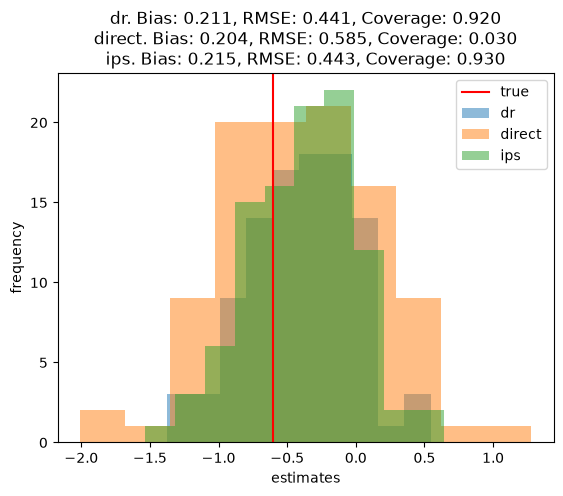

Now trying true_f_simple_nonlin_conf


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 28 concurrent workers.
[Parallel(n_jobs=-1)]: Done 100 out of 100 | elapsed: 10.3min finished


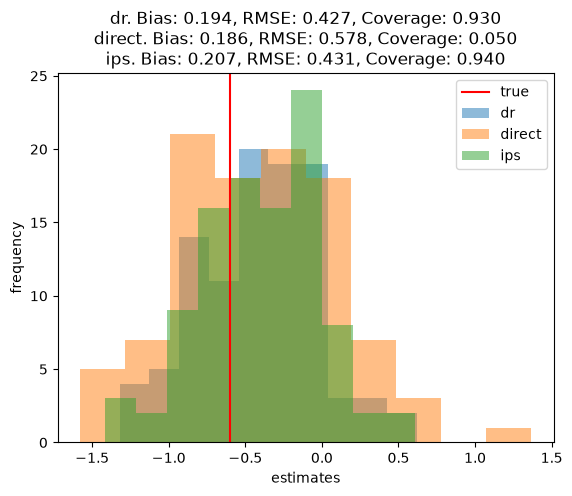

Now trying true_f_compl_lin_conf


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 28 concurrent workers.
[Parallel(n_jobs=-1)]: Done 100 out of 100 | elapsed: 10.6min finished


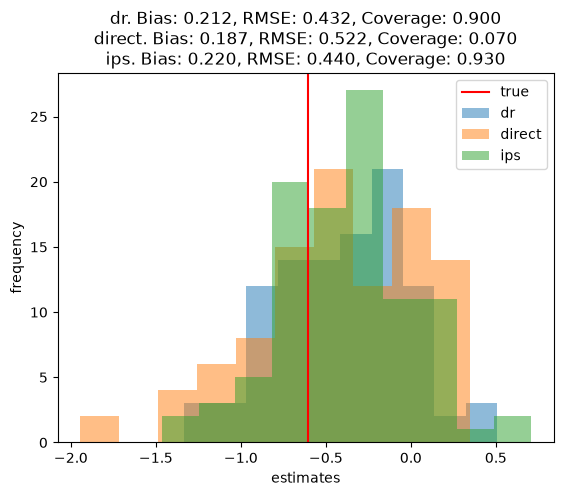

Now trying true_f_compl_nonlin_conf


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 28 concurrent workers.
[Parallel(n_jobs=-1)]: Done 100 out of 100 | elapsed:  9.3min finished


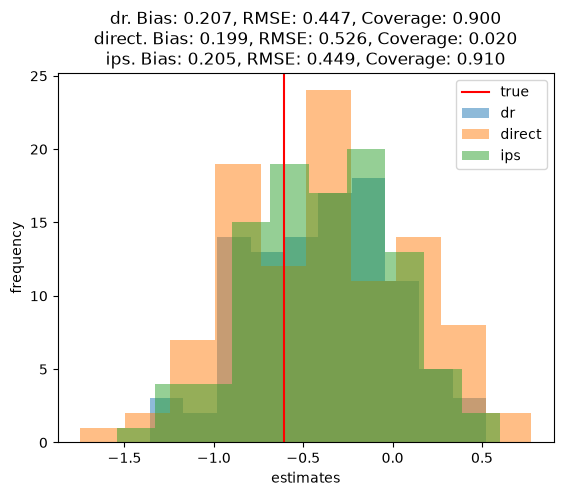

Now trying true_f_simple_lin_conf


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 28 concurrent workers.
[Parallel(n_jobs=-1)]: Done 100 out of 100 | elapsed:  9.3min finished


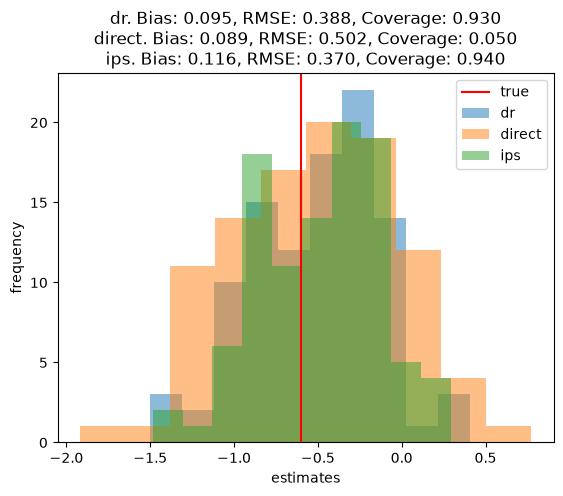

Now trying true_f_simple_nonlin_conf


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 28 concurrent workers.
[Parallel(n_jobs=-1)]: Done 100 out of 100 | elapsed: 10.8min finished


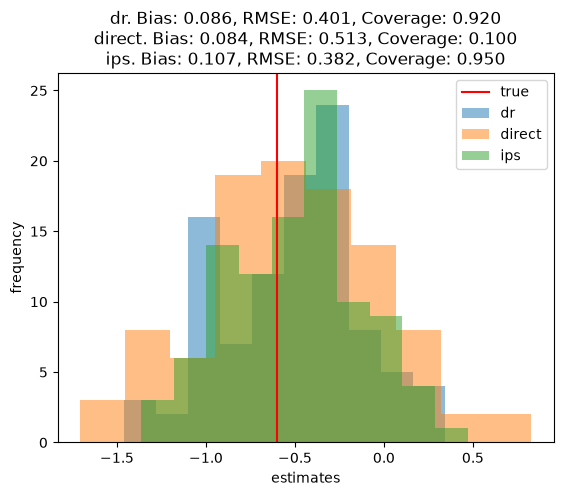

Now trying true_f_compl_lin_conf


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 28 concurrent workers.
[Parallel(n_jobs=-1)]: Done 100 out of 100 | elapsed:  9.7min finished


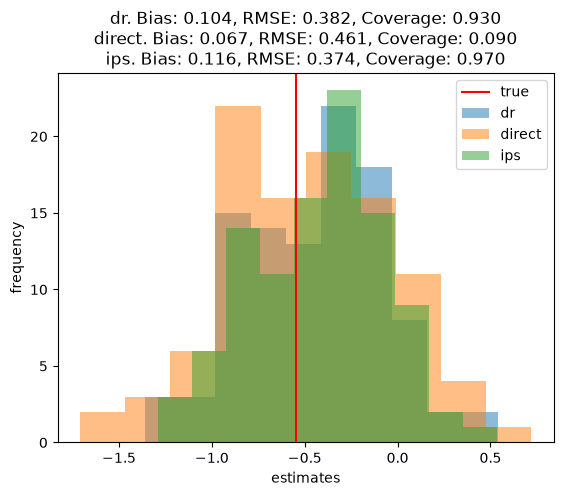

Now trying true_f_compl_nonlin_conf


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 28 concurrent workers.
[Parallel(n_jobs=-1)]: Done 100 out of 100 | elapsed: 10.6min finished


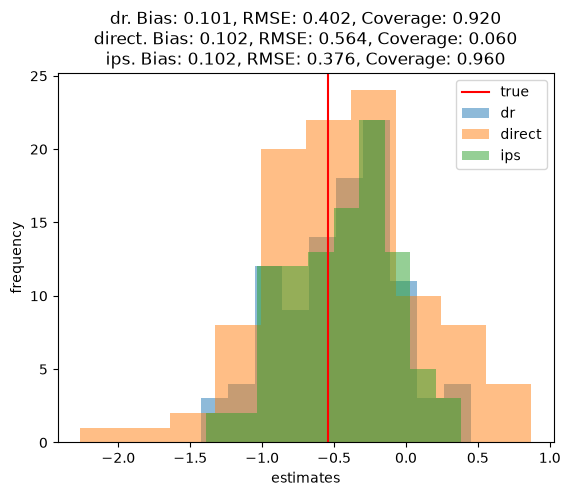

In [9]:
for i in range(3):
    np.random.seed(i)

    b = np.random.uniform(-0.5, 0.5, size=(20, 1))
    c = np.random.uniform(-0.2, 0.2, size=(8, 1))

    def nonlin(X):
        return 1.5*scipy.special.expit(10 * X[:, 6]) + 1.5*scipy.special.expit(10 * X[:, 8])

    def true_f_simple(X):
        return -0.6 * X[:, 0]

    def true_f_simple_lin_conf(X):
        return true_f_simple(X) + np.matmul(X[:, 1:21], b).flatten()

    def true_f_simple_nonlin_conf(X):
        return true_f_simple_lin_conf(X) + nonlin(X)

    def true_f_compl(X):
        return -0.5 * (X[:, 1]**2/10 + .5) * X[:, 0]**3 / 3

    def true_f_compl_lin_conf(X):
        return -0.5 * (X[:, 1]**2/10 + np.matmul(X[:, 1:9], c).flatten() + .5) * X[:, 0]**3 / 3 + np.matmul(X[:, 1:21], b).flatten()

    def true_f_compl_nonlin_conf(X):
        return true_f_compl_lin_conf(X) + nonlin(X)

    #for true_f in [true_f_simple, true_f_simple_lin_conf, true_f_simple_nonlin_conf,
    #               true_f_compl, true_f_compl_lin_conf, true_f_compl_nonlin_conf]:
    for true_f in [true_f_simple_lin_conf, true_f_simple_nonlin_conf,
                   true_f_compl_lin_conf, true_f_compl_nonlin_conf]:
        print("Now trying " + true_f.__name__)

        def gen_y(X):
            n = X.shape[0]
            return true_f(X) + np.random.normal(0, np.sqrt(5.6 * np.var(true_f(X))), size = (n,))

        path = './results/BHP/RieszNet/' + true_f.__name__
        if not os.path.exists(path):
            os.makedirs(path)

        namedata = path + "/seed_" + str(i) + '.joblib'
        nameplot = path + "/seed_" + str(i) + '.pdf'
        sim_fun(W, moment_fn = avg_small_diff, n_hidden = n_hidden, drop_prob = drop_prob, 
                true_reg = true_f, true_rr = true_rr, gen_y = gen_y, gen_T = gen_T, 
                N_sim = 100, fast_train_opt = fast_train_opt, train_opt = train_opt,
                seed = i, verbose = 1, plot = True, save = namedata, saveplot = nameplot)

## Summary Outputs

### LaTeX Table

In [ ]:
f_string = ["1. Simple $f$",
            "2. Simple $f$ with linear confound.",
            "3. Simple $f$ with linear and non-linear confound.",
            "4. Complex $f$",
            "5. Complex $f$ with linear confound.",
            "6. Complex $f$ with linear and non-linear confound."]

true_fs = ['true_f_simple', 'true_f_simple_lin_conf', 'true_f_simple_nonlin_conf',
           'true_f_compl', 'true_f_compl_lin_conf', 'true_f_compl_nonlin_conf']

methods = ['direct', 'ips', 'dr']
    
with open("./results/BHP/RieszNet/res_avg_der_NN.tex", "w") as f:
    f.write("\\begin{tabular}{*{11}{r}} \n" +
            "\\toprule \n" +
            "&& \\multicolumn{3}{c}{Direct} & \\multicolumn{3}{c}{IPS} & \\multicolumn{3}{c}{DR} \\\\ \n" +
            "\\cmidrule(lr){3-5} \\cmidrule(lr){6-8} \\cmidrule(lr){9-11} \n" +
            "reg $R^2$ &  rr $R^2$ &  Bias &  RMSE &  Cov. &  Bias &  RMSE &  Cov. &  Bias &  RMSE &  Cov. \\\\ \n" +
            "\\midrule \n")
    
    for f_i, true_f in enumerate(true_fs):
        path = './results/BHP/RieszNet/' + true_f
        f.write("\\addlinespace \n \\multicolumn{11}{l}{\\textbf{" + f_string[f_i] + "}} \\\\ \n")
        
        r2_reg, r2_rr = [], []
        res = {}
        for method in methods:
            res[method] = {'bias': [], 'rmse': [], 'cov': []}
            
        for i in range(10):
            namedata = path + '/seed_' + str(i) + '.joblib'
            loaded = load(namedata)
            r2_reg = np.append(r2_reg, loaded[2])
            r2_rr = np.append(r2_rr, loaded[4])
                
            for method in methods:
                res[method]['bias'].append(loaded[0][method]['bias'])
                res[method]['rmse'].append(loaded[0][method]['rmse'])
                res[method]['cov'].append(loaded[0][method]['cov'])
            
        f.write(" & ".join(["{:.3f}".format(np.mean(x)) for x in [r2_reg, r2_rr]]) + " & ")
        f.write(" & ".join(["{:.3f}".format(np.mean(res[method][x])) for method in methods
                            for x in ['bias', 'rmse', 'cov']]) + " \\\\ \n")

    f.write("\\bottomrule \n \\end{tabular}")

### Histograms over 10 Seeds

In [ ]:
for true_f in true_fs: 
    
    path = './results/BHP/RieszNet/' + true_f
    
    rmse_reg, r2_reg, rmse_rr, r2_rr, ipsbias, drbias, truth = [], [], [], [], [], [], []
    res = {}
            
    for method in methods:
        res[method] = {'point' : [], 'bias': [], 'rmse': [], 'cov': []}
            
    for i in range(10):
        namedata = path + '/seed_' + str(i) + '.joblib'
        loaded = load(namedata)
        rmse_reg = np.append(rmse_reg, loaded[1])
        r2_reg = np.append(r2_reg, loaded[2])
        rmse_rr = np.append(rmse_rr, loaded[3])
        r2_rr = np.append(r2_rr, loaded[4])
        ipsbias = np.append(ipsbias, loaded[5])
        drbias = np.append(drbias, loaded[6])
        truth = np.append(truth, loaded[7])
                
        for method in methods:
            res[method]['point'] = np.append(res[method]['point'], loaded[0][method]['point'])
            res[method]['bias'].append(loaded[0][method]['bias'])
            res[method]['rmse'].append(loaded[0][method]['rmse'])
            res[method]['cov'].append(loaded[0][method]['cov'])
            
    nuisance_str = ("reg RMSE: {:.3f}, R2: {:.3f}, rr RMSE: {:.3f}, R2: {:.3f}\n"
                    "IPS orthogonality: {:.3f}, DR orthogonality: {:.3f}").format(np.mean(rmse_reg), np.mean(r2_reg),
                                                                                          np.mean(rmse_rr), np.mean(r2_rr),
                                                                                          np.mean(ipsbias), np.mean(drbias))
    method_strs = ["{}. Bias: {:.3f}, RMSE: {:.3f}, Coverage: {:.3f}".format(method, np.mean(d['bias']), np.mean(d['rmse']), np.mean(d['cov']))
                    for method, d in res.items()]
    plt.title("\n".join([nuisance_str] + method_strs))
    for method, d in res.items():
        plt.hist(np.array(d['point']), alpha=.5, label=method)
    plt.axvline(x = np.mean(truth), label='true', color='red')
    plt.legend()
    nameplot = path + '/all.pdf'
    plt.savefig(nameplot, bbox_inches='tight')
    plt.show()